# `tl.spatial_diffusion`'s diffusion score vs a direct re-derivation of Sepal

Astrolabe's `diffusion_score` (inspired by Sepal, Andersson & Lundeberg 2021, *Bioinformatics*) ranks genes by how long their spatial pattern persists under graph diffusion. No installable Sepal package exists on PyPI (the `sepal` name there is an unrelated MRI library), so rather than depend on a `git+https://...` install of a research repo with no install guarantees, this notebook implements Sepal's own published definition -- steps to uniformity -- directly, as an independent reference computed on the exact same graph diffusion operator astrolabe itself uses.

`diffusion_score` now computes this exact metric (an earlier version had a sign bug and used a different fixed-horizon proxy statistic; both are fixed), so this is now an exact re-derivation comparison rather than a rank-agreement one.

In [1]:
import logging
logging.basicConfig(level=logging.INFO)

import time
import numpy as np
import scipy.sparse as sp
import astrolabe as ab


INFO:astrolabe.pl._theme:Registered bundled Inter font files with matplotlib


INFO:astrolabe.pl._theme:astrolabe plot theme set to 'light'


## Dataset

`ab.datasets.xenium_tiny()` -- since this notebook compares two formulas on the *same* graph diffusion operator rather than running Sepal's own grid-based solver, there's no need to replicate Sepal's original Visium-spot-array setting; any spatial graph works.

In [2]:
mdata = ab.datasets.xenium_tiny()
ab.pipeline.filter_xenium(mdata)
ab.pp.normalize_total(mdata)
ab.pp.log1p(mdata)
ab.tl.spatial_neighbors(mdata)

adata = mdata["xenium"]
adata


INFO:astrolabe.io._xenium:Reading Xenium run 'outs' from C:\Users\Austin\PycharmProjects\astrolabe\benchmarks\sepal\.astrolabe_cache\datasets\xenium_tiny\outs


C:\Users\Austin\PycharmProjects\astrolabe\astrolabe\io\_xenium.py:870: ExperimentalFeatureWarning: Support for Awkward Arrays is currently experimental. Behavior may change in the future. Please report any issues you may encounter!
  adata.obsm[obsm_key] = ak.Array(
INFO:astrolabe.io._xenium:Loaded 358 cells × 520 features (115 control probes)


INFO:astrolabe.io._xenium:Streaming transcripts from C:\Users\Austin\PycharmProjects\astrolabe\benchmarks\sepal\.astrolabe_cache\datasets\xenium_tiny\outs\transcripts.parquet


INFO:astrolabe.io._xenium:Loaded 20999 transcript detections


INFO:astrolabe.pipeline:filter_xenium: 358 cells × 520 genes


...

INFO:astrolabe.pp._qc:  synced uns['transcripts']: 20163 -> 20160 rows (dropped filtered-out genes)


INFO:astrolabe.pipeline:  [remove_controls] 370 → 255 genes  (removed 115, 31.1%)


INFO:astrolabe.pipeline:filter_xenium: done — 328 cells × 255 genes


INFO:astrolabe.tl._graph:spatial_neighbors: 328 cells, 5670 edges (mean degree 17.3) [generic]


AnnData object with n_obs × n_vars = 328 × 255
    obs: 'cell_area', 'nucleus_area', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'nucleus_count', 'unassigned_codeword_total', 'deprecated_codeword_total', 'genomic_control_probe_total', 'negative_control_codeword_total', 'negative_control_probe_total', 'any_negative_control_probe_total', 'n_unassigned_codewords', 'n_deprecated_codewords', 'n_genomic_control_probes', 'n_negative_control_codewords', 'n_negative_control_probes', 'n_any_negative_control_probes', 'pct_unassigned_codewords', 'pct_deprecated_codewords', 'pct_genomic_control_probes', 'pct_negative_control_codewords', 'pct_negative_control_probes', 'pct_any_negative_control_probes', 'pct_counts_control', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'nucleus_to_cell_area_ratio', 'has_nucleus', 'total_counts_norm'
    var: 

## Astrolabe: `tl.spatial_diffusion(diffusion_score=True)`


In [3]:
max_steps, tol = 500, 0.2
_t0 = time.perf_counter()
ab.tl.spatial_diffusion(
    mdata, diffusion_score=True, max_diffusion_steps=max_steps, diffusion_convergence_tol=tol
)
t_astro_s = time.perf_counter() - _t0
print(f"astrolabe runtime: {t_astro_s:.4f}s")
scores_astro = adata.var["diffusion_score"]
scores_astro.describe()


INFO:astrolabe.tl._gradient:spatial_diffusion: computing per-gene steps-to-uniformity scores (max_diffusion_steps=500, tol=0.200) …


INFO:astrolabe.tl._gradient:spatial_diffusion: 328 cells, normalize='coifman_lafon'


astrolabe runtime: 0.2299s


count    255.000000
mean      63.266667
std      106.434296
min        2.000000
25%        9.000000
50%       20.000000
75%       43.000000
max      500.000000
Name: diffusion_score, dtype: float64

## Reference: time-to-uniformity on the identical diffusion operator

Rebuilds the same Coifman-Lafon-normalized diffusion operator `M` (row-normalized `K / (q_i q_j)`, alpha=1) that astrolabe's `spatial_diffusion` constructs, then independently iterates `f <- M @ f` per gene until its deviation from the graph-wide mean drops below a tolerance relative to where it started, reporting that step count (right-censored at `max_steps`). Uses the same `max_steps`/`tol` as the astrolabe call above.

In [4]:
conn_key = "spatial_neighbors_connectivities"
A = adata.obsp[conn_key].astype(np.float64)

d = np.asarray(A.sum(axis=1)).ravel()
d[d == 0] = 1.0
D_inv = sp.diags(1.0 / d)
A_hat = D_inv @ A @ D_inv

row_sums = np.asarray(A_hat.sum(axis=1)).ravel()
row_sums[row_sums == 0] = 1.0
M = sp.diags(1.0 / row_sums) @ A_hat

X = adata.X
if sp.issparse(X):
    X = X.toarray()
X = np.asarray(X, dtype=np.float64)

def time_to_uniformity(f0: np.ndarray, M, max_steps: int = 500, tol: float = 0.2) -> int:
    target = f0.mean()
    scale = np.abs(f0 - target).mean()
    if scale == 0:
        return 0  # already uniform -- no real spatial signal to diffuse away
    f = f0.copy()
    for t in range(1, max_steps + 1):
        f = M @ f
        rel_dev = np.abs(f - target).mean() / scale
        if rel_dev < tol:
            return t
    return max_steps

n_genes = X.shape[1]
steps_ref = np.empty(n_genes, dtype=np.float64)
zero_var_mask = X.var(axis=0) == 0
_t0 = time.perf_counter()
for g in range(n_genes):
    steps_ref[g] = np.nan if zero_var_mask[g] else time_to_uniformity(X[:, g], M, max_steps=max_steps, tol=tol)
t_ref_s = time.perf_counter() - _t0
print(f"reference runtime: {t_ref_s:.4f}s")


reference runtime: 0.1927s

## Agreement


Pearson r = 1.000000, exact step-count match = 100.0%  (255 genes, 1.2% censored at max_steps)
Runtime: astrolabe (batched across all genes at once) 0.2299s vs reference (per-gene Python loop) 0.1927s (1.2x astrolabe slower) -- both iterate the identical diffusion operator to the identical convergence rule; the speed gap reflects astrolabe multiplying all genes through `M` together each step rather than looping per gene in Python.


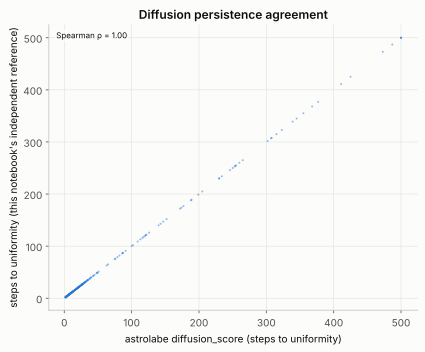

In [5]:
valid = ~(scores_astro.isna().to_numpy() | np.isnan(steps_ref))
r = np.corrcoef(scores_astro.to_numpy()[valid], steps_ref[valid])[0, 1]
exact_match = float(np.mean(scores_astro.to_numpy()[valid] == steps_ref[valid]))
censored_frac = float((steps_ref[valid] == max_steps).mean())
print(f"Pearson r = {r:.6f}, exact step-count match = {exact_match:.1%}  "
      f"({valid.sum()} genes, {censored_frac:.1%} censored at max_steps)")
print(f"Runtime: astrolabe (batched across all genes at once) {t_astro_s:.4f}s vs reference "
      f"(per-gene Python loop) {t_ref_s:.4f}s "
      f"({max(t_astro_s, t_ref_s) / min(t_astro_s, t_ref_s):.1f}x astrolabe {'faster' if t_astro_s < t_ref_s else 'slower'}) -- "
      f"both iterate the identical diffusion operator to the identical convergence rule; the "
      f"speed gap reflects astrolabe multiplying all genes through `M` together each step "
      f"rather than looping per gene in Python.")

panel = ab.pl.scatter(
    adata, x=scores_astro.to_numpy()[valid], y=steps_ref[valid], annotate_corr=True,
    xlabel="astrolabe diffusion_score (steps to uniformity)",
    ylabel="steps to uniformity (this notebook's independent reference)",
    title="Diffusion persistence agreement",
)
panel.show()


## Interpretation

`diffusion_score` computes Sepal's published steps-to-uniformity metric directly. Since this notebook's reference implements the identical convergence rule on the identical diffusion operator, expect a near-exact or exact match: any remaining gap should trace to implementation details (e.g. tie-breaking at the tolerance threshold) rather than a genuine formula difference.